# Progress Check 2: ML anomaly detection for Kubernetes autoscaling
Pilot data from the real `hpa-lab` cluster (made by `run_scenarios.py`, exported by `export_runs.py`). Uses the same functions as `evaluate.py`.

## 1. Dataset

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import evaluate as ev
%matplotlib inline
raw = pd.read_csv('data/dataset.csv')
raw = raw[raw.in_run == 1]
print(raw.shape)
raw.groupby('run').agg(rows=('label','size'), attack_rows=('label','sum'),
                       max_replicas=('replicas','max'), max_cpu=('cpu_utilization','max'),
                       max_req_s=('request_rate','max')).round(1)

(58, 19)


,rows,attack_rows,max_replicas,max_cpu,max_req_s
run,,,,,
attack_flood,33,10,10,644.8,617.4
normal_steady,25,0,6,15.9,3.5


In [2]:
raw[['timestamp','replicas','cpu_utilization','request_rate','latency_p95_s','label','phase']].head()

,timestamp,replicas,cpu_utilization,request_rate,latency_p95_s,label,phase
4,1.793296e+09,6,0.343813,0.000000,0.00000,0,baseline
5,1.793296e+09,6,1.692370,0.396578,0.04875,0,baseline
6,1.793296e+09,6,6.024797,1.491347,0.04875,0,baseline
7,1.793296e+09,6,12.090868,2.491322,0.04875,0,baseline
8,1.793296e+09,6,14.507408,3.570176,0.04875,0,baseline


## 2. Data preparation and features
Missing rate/latency filled with 0, derived features per run. Target = `label` (1 = attack).

In [3]:
ev.SPLIT.pop('test', None)   # pilot has no test runs yet; the test set stays unused
df = ev.load('data/dataset.csv')
features = ev.FEATURE_SETS['B_extended']
print('features:', features)
print('missing values:', int(df[features].isna().sum().sum()))
df[features + ['label']].describe().round(2)

features: ['replicas', 'cpu_utilization', 'request_rate', 'cpu_per_request', 'latency_p95_s', 'replica_changes_5m', 'cpu_std_5m']
missing values: 0


,replicas,cpu_utilization,request_rate,cpu_per_request,latency_p95_s,replica_changes_5m,cpu_std_5m,label
count,58.00,58.00,58.00,58.00,58.00,58.00,58.00,58.00
mean,7.14,112.20,100.18,3.08,0.04,1.03,90.43,0.17
std,2.59,196.82,188.04,1.63,0.01,0.79,110.10,0.38
min,1.00,0.06,0.00,0.06,0.00,0.00,0.00,0.00
25%,6.00,14.00,3.40,1.10,0.03,0.00,5.10,0.00
50%,6.00,14.87,3.47,4.05,0.05,1.00,6.40,0.00
75%,10.00,38.59,71.43,4.29,0.05,2.00,219.98,0.00
max,10.00,644.75,617.44,4.94,0.05,2.00,255.06,1.00


## 3. Split by whole run
Train = normal rows of the train runs only. Validation = tuning. Test = used once at the end.

In [4]:
train = df[(df.split == 'train') & (df.label == 0)]
val = df[df.split == 'validation'].reset_index(drop=True)
df.groupby(['split','run']).label.agg(rows='size', attack_rows='sum')

,,rows,attack_rows
split,run,,
train,normal_steady,25,0
validation,attack_flood,33,10


## 4. Model: Isolation Forest (scaler fitted on train only), contamination sweep on validation

In [5]:
keep = ev.scored_mask(val, 60)
rows = []
for c in [0.01, 0.05, 0.1, 0.15, 0.2]:
    for seed in range(5):
        m = ev.fit_iforest(train[features], c, seed)
        flag, score = ev.iforest_outputs(m, val[features])
        r = ev.evaluate_flags(val, flag, score, keep); r['contamination'] = c; rows.append(r)
sweep = pd.DataFrame(rows).groupby('contamination')[['precision','recall','f1','fpr']].mean().round(3)
sweep

,precision,recall,f1,fpr
contamination,,,,
0.01,0.000,0.00,0.000,0.067
0.05,0.000,0.00,0.000,0.067
0.10,0.000,0.00,0.000,0.120
0.15,0.180,0.08,0.110,0.173
0.20,0.479,0.52,0.493,0.267


## 5. Preliminary results (validation)

chosen contamination: 0.2


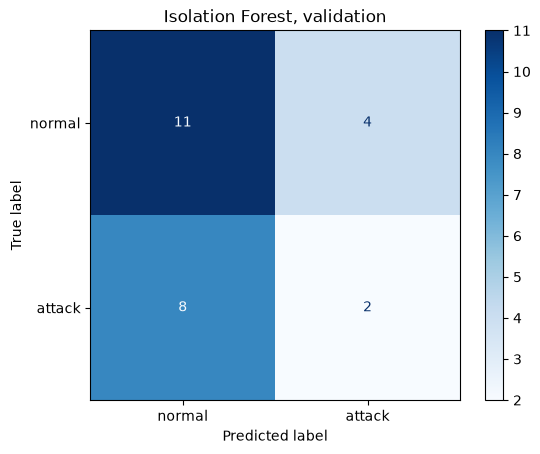

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
best_c = sweep.f1.idxmax()
m = ev.fit_iforest(train[features], best_c, 0)
flag, score = ev.iforest_outputs(m, val[features])
print('chosen contamination:', best_c)
ConfusionMatrixDisplay.from_predictions(val.label[keep], np.asarray(flag)[keep],
                                        display_labels=['normal','attack'], cmap='Blues')
plt.title('Isolation Forest, validation'); plt.show()

In [7]:
pd.read_csv('results_pilot/baselines.csv').round(3)

,detector,contamination,precision,recall,f1,fpr,tp,fp,fn,tn,...,avg_precision,episodes,episodes_detected,episode_recall,latency_mean_s,latency_max_s,precision_std,recall_std,f1_std,fpr_std
0,"Isolation Forest (B_extended, c=0.2)",0.2,0.479,0.52,0.493,0.267,5.2,4.0,4.8,11.0,...,0.551,2.0,1.4,0.7,16.125,17.25,0.277,0.349,0.311,0.042
1,CPU threshold (> 15.7%),NaN,1.000,0.90,0.947,0.000,9.0,0.0,1.0,15.0,...,0.967,2.0,2.0,1.0,9.000,15.00,NaN,NaN,NaN,NaN
2,"rolling z-score (window 8, k=2.25)",NaN,1.000,0.70,0.824,0.000,7.0,0.0,3.0,15.0,...,0.891,2.0,2.0,1.0,24.000,33.00,NaN,NaN,NaN,NaN


## 6. Evidence: validation run over time

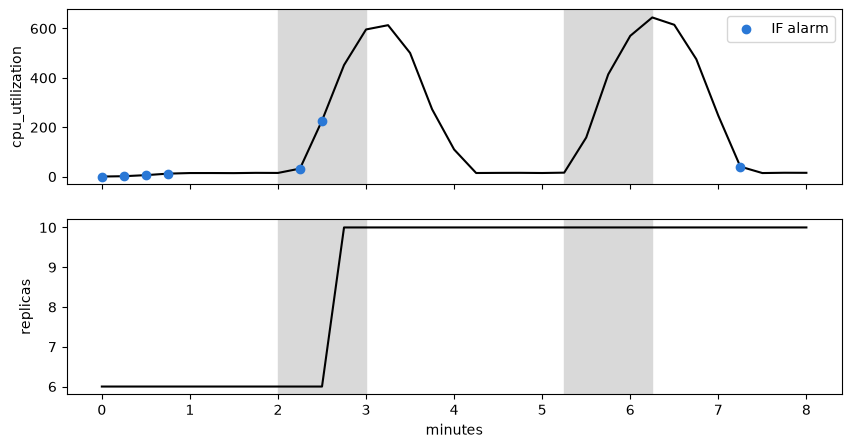

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
t = (val.timestamp - val.timestamp.min()) / 60
for a, col in zip(ax, ['cpu_utilization', 'replicas']):
    a.plot(t, val[col], 'k'); a.set_ylabel(col)
    a.fill_between(t, 0, 1, where=val.label == 1, transform=a.get_xaxis_transform(), color='0.85')
ax[0].scatter(t[np.asarray(flag) == 1], val.cpu_utilization[np.asarray(flag) == 1], c='#2a78d6', label='IF alarm', zorder=3)
ax[0].legend(); ax[1].set_xlabel('minutes'); plt.show()

## Next steps
- Run all 7 scenarios (~2 h) for more normal data and all attack types
- Re-tune on validation, compare feature sets A–D
- `python3 evaluate.py --final` once on the test set